# PGD-MaxEnt — minimal working example

**Notation** (consistent with the notes)

| Symbol | Meaning |
|--------|----------|
| $d$ | dimension |
| $\Sigma^*$ | true covariance ($d\times d$, SPD) |
| $S$ | observed index pairs (lower-triangle convention, diagonal always included) |
| $a_{ij}$ | noisy observation at $(i,j)\in S$ |
| $A$ | $d\times d$ matrix: $A_{ij}=a_{ij}$ on $S$, $0$ elsewhere |
| $K(z)$ | precision matrix parameterised by $z\in \mathbb{R}^{\|S\|}$ |
| $\hat\Sigma$ | estimated covariance $= K(z^*)^{-1}$ |

**Algorithm (two stages)**

- **Stage A (PGD):** find the nearest SPD matrix $\tilde X$ whose entries on $S$ fit $A$  
- **Stage B (MaxEnt):** find the max-entropy completion of $\tilde X|_S$ by solving the dual $\min_z \ell(z) = -\log|K(z)| + \operatorname{tr}(K(z)\,\tilde X)$

## Imports

In [100]:
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

In [8]:
def project_psd(X, thresh=1e-8):
    """Project X to the PSD cone by clipping eigenvalues to thresh."""
    vals, vecs = np.linalg.eigh(X)
    return vecs @ np.diag(np.maximum(vals, thresh)) @ vecs.T

## Stage A — Projected Gradient Descent

Minimise the weighted squared-error objective
$$
f(X) = \sum_{(i,j)\in S} \frac{1}{\tau_{ij}^2}(X_{ij}-a_{ij})^2
\quad\text{subject to }X\succeq 0,
$$
where $\tau_{ij}$ is the noise standard deviation for entry $(i,j)$.

**Symmetric rewrite** (for gradient derivation, same value as above):
$$
f(X) = \sum_i \frac{1}{\tau_{ii}^2}(X_{ii}-a_{ii})^2
      + \frac{1}{2}\sum_{(i,j)\in E}\frac{1}{\tau_{ij}^2}(X_{ij}-a_{ij})^2,
$$
where $E=\{(i,j):i\neq j,\,(i,j)\in S\text{ or }(j,i)\in S\}$.  The gradient is
$$
[\nabla f(X)]_{ij} =
\begin{cases}
\dfrac{2}{\tau_{ii}^2}(X_{ii}-a_{ii}) & i=j \\[4pt]
\dfrac{1}{\tau_{ij}^2}(X_{ij}-a_{ij}) & (i,j)\in E \\[4pt]
0 & \text{otherwise.}
\end{cases}
$$

**Weight normalisation.**  Let $w_{ij}=1/\tau_{ij}^2$.  Before running PGD, rescale
$\tilde w_{ij} = w_{ij}/\max_{S} w$.  The normalised objective $\tilde f = f/\max w$
has the same minimiser and makes the step size $\eta$ comparable across problem instances.

In [9]:
def stage_a(A, inds, tau, eta=0.1, n_iters=2000, tol=1e-8, track_kkt=False):
    """
    Inputs
    ------
    A         : (d,d) observation matrix (zero at unobserved entries)
    inds      : (m,2) observed index pairs, lower-triangle including diagonal
    tau       : (m,)  noise std-dev for each entry in inds
    eta       : initial step size
    track_kkt : if True, compute and store KKT diagnostics each iteration
                (requires two eigendecompositions per step — disable for speed)

    Returns
    -------
    X    : (d,d) PSD matrix with X_S ≈ A_S
    hist : list of per-iteration dicts; KKT fields present only if track_kkt=True
    """
    d = A.shape[0]

    # Normalised weights: w̃_k = (1/τ_k²) / max_k(1/τ_k²)
    w = 1.0 / tau ** 2
    w = w / w.max()

    W = np.zeros((d, d))
    W[inds[:, 0], inds[:, 1]] = w
    W[inds[:, 1], inds[:, 0]] = w          # symmetric (no-op for diagonal)
    mask = W > 0

    def objective(X):
        r = X[inds[:, 0], inds[:, 1]] - A[inds[:, 0], inds[:, 1]]
        return np.sum(w * r ** 2)

    # Backtracking line search parameters
    armijo = 0.5    # sufficient decrease constant
    beta   = 0.5    # step size decrease factor on backtrack
    gamma  = 1.05   # step size increase factor after a successful step

    X = project_psd(A.copy())
    hist = []

    for t in range(n_iters):
        # Gradient at current X
        G = np.where(mask, W * (X - A), 0.0)
        G[np.arange(d), np.arange(d)] *= 2
        obj = objective(X)

        # Armijo backtracking line search for PGD.
        # Condition: f(X_new) ≤ f(X) − (armijo/η)‖X_new − X‖²
        for _ in range(50):
            X_new = project_psd(X - eta * G)
            delta = np.linalg.norm(X_new - X, 'fro')
            if objective(X_new) <= obj - armijo * delta ** 2 / eta:
                break
            eta *= beta
            if eta < 1e-14:
                break

        entry = {
            'obj':       obj,
            'delta':     delta,
            'grad_norm': np.linalg.norm(G, 'fro'),
            'eta':       eta,
        }

        if track_kkt:
            # Computed at current X (before the step) where G was evaluated
            entry['min_eig_X']  = np.linalg.eigvalsh(X).min()
            entry['min_eig_G']  = np.linalg.eigvalsh(G).min()
            entry['comp_slack'] = abs(np.sum(G * X))

        hist.append(entry)
        X    = X_new
        eta *= gamma    # modest increase; keeps eta near the local Lipschitz scale

        if delta < tol:
            break

    return X, hist

## Stage B — Maximum Entropy completion

Given the Stage A output $\tilde X$, solve the dual of the max-entropy completion:
$$
\min_{z\in\mathbb{R}^{|S|}} \;\ell(z) = -\log|K(z)| + \operatorname{tr}\bigl(K(z)\,\tilde X\bigr)
$$
Gradient:
$$
\frac{\partial\ell}{\partial z_k} =
\begin{cases}
\tilde X_{ii} - \Sigma_{ii} & i=j \\
2(\tilde X_{ij} - \Sigma_{ij}) & i\neq j
\end{cases},
\qquad \Sigma = K(z)^{-1}.
$$
At the optimum $\hat\Sigma_{ij} = \tilde X_{ij}$ for all $(i,j)\in S$, and $K(z^*)_{ij}=0$ outside $S$.

In [10]:
def build_K(z, inds, d):
    """
    Build the symmetric precision matrix K(z).
    K[i,j] = K[j,i] = z[k]  for (i,j) = inds[k].
    (For diagonal entries the two writes coincide, so K[i,i] = z[k].)
    """
    K = np.zeros((d, d))
    K[inds[:, 0], inds[:, 1]] = z
    K[inds[:, 1], inds[:, 0]] = z
    return K


def stage_b(X_psd, inds, n_iters=500):
    """
    Inputs
    ------
    X_psd  : (d,d) PSD matrix from Stage A  (plays the role of 'a' in the dual)
    inds   : (m,2) observed index pairs

    Returns
    -------
    Sigma_hat : (d,d) max-entropy covariance estimate
    hist      : list of per-iteration dicts:
                  loss            : dual objective -log|K| + tr(K X̃)
                  constraint_viol : rms( Σ̂_S - X̃_S )  (→ 0 at convergence)
                  grad_norm       : ‖∇ℓ(z)‖             (→ 0 at convergence)
                  min_eig_K       : λ_min(K)             (stays > 0 if K remains PD)
    """
    d = X_psd.shape[0]
    rows, cols = inds[:, 0], inds[:, 1]
    diag_mask = rows == cols

    hist = []

    def loss_and_grad(z):
        K = build_K(z, inds, d)
        sign, logdet_K = np.linalg.slogdet(K)
        if sign <= 0:
            return 1e15, np.zeros_like(z)
        Sigma = np.linalg.inv(K)
        loss = -logdet_K + np.sum(K * X_psd)
        mult = np.where(diag_mask, 1.0, 2.0)
        grad = mult * (X_psd[rows, cols] - Sigma[rows, cols])
        return float(loss), grad

    def callback(z):
        K = build_K(z, inds, d)
        sign, logdet_K = np.linalg.slogdet(K)
        if sign <= 0:
            return
        Sigma = np.linalg.inv(K)
        loss = -logdet_K + np.sum(K * X_psd)
        mult = np.where(diag_mask, 1.0, 2.0)
        grad = mult * (X_psd[rows, cols] - Sigma[rows, cols])
        hist.append({
            'loss':            float(loss),
            'constraint_viol': float(np.sqrt(np.mean((Sigma[rows, cols] - X_psd[rows, cols]) ** 2))),
            'grad_norm':       float(np.linalg.norm(grad)),
            'min_eig_K':       float(np.linalg.eigvalsh(K).min()),
        })

    z0 = np.where(diag_mask, 1.0 / np.maximum(X_psd[rows, cols], 1e-6), 0.0)

    result = minimize(
        loss_and_grad, z0,
        method='L-BFGS-B', jac=True,
        callback=callback,
        options={
            'maxiter': n_iters,
            'ftol':    1e-8,
            'gtol':    1e-8,
        },
    )

    K_opt = build_K(result.x, inds, d)
    #Sigma_hat = project_psd(np.linalg.inv(K_opt))
    Sigma_hat = np.linalg.inv(K_opt)
    return Sigma_hat, hist

## Full pipeline

In [11]:
def pgd_maxent(A, inds, tau, eta=0.01, pgd_iters=2000, lbfgs_iters=500, tol=1e-8, track_kkt=False):
    """
    Full pipeline.  Returns (Sigma_hat, hist_a, hist_b).
    track_kkt : passed to stage_a; enables KKT diagnostics at extra compute cost.
    """
    print("Stage A: PGD...")
    X_psd, hist_a = stage_a(A, inds, tau, eta=eta, n_iters=pgd_iters, tol=tol, track_kkt=track_kkt)
    r = X_psd[inds[:, 0], inds[:, 1]] - A[inds[:, 0], inds[:, 1]]
    print(f"  {len(hist_a)} iters | obs residual rms = {np.sqrt(np.mean(r**2)):.2e}"
          f" | min eig = {np.linalg.eigvalsh(X_psd).min():.2e}")

    print("Stage B: MaxEnt (L-BFGS)...")
    Sigma_hat, hist_b = stage_b(X_psd, inds, n_iters=lbfgs_iters)
    print(f"  {len(hist_b)} iters | final loss = {hist_b[-1]['loss']:.4e}"
          f" | constraint viol rms = {hist_b[-1]['constraint_viol']:.2e}")

    return Sigma_hat, hist_a, hist_b

## Synthetic problem

In [104]:
def make_problem(
    d           = 8,
    fraction_offidiag = 0.25,     # fraction of off-diagonal entries observed
    tau_diag    = 0.1,      # noise std-dev for all diagonal entries
    num_anneal_phases  = 2,        # decrease off-diagonal τ this many times as we add measurements
    anneal_by   = 2.0,      # multiplicative decrease factor
    seed        = 42,
):
    """
    Returns
    -------
    Sigma_true : (d,d) true covariance
    A          : (d,d) noisy observation matrix (zero at unobserved entries)
    inds       : (m,2) observed pairs, lower-triangle including diagonal
    tau        : (m,)  noise std-dev for each entry in inds
    """
    rng = np.random.default_rng(seed)

    # True covariance
    Q, _ = np.linalg.qr(rng.standard_normal((d, d)))
    eigvals = np.clip(np.exp(rng.standard_normal(d)), 0.1, 10.0)
    Sigma_true = Q @ np.diag(eigvals) @ Q.T

    n_offdiag = int(fraction_offidiag * (d * (d - 1) // 2))

    # Observation index set S
    diag_inds    = [(i, i) for i in range(d)]
    pool         = [(i, j) for i in range(d) for j in range(i + 1, d)]
    chosen       = rng.choice(len(pool), min(n_offdiag, len(pool)), replace=False)
    off_diag_inds = [pool[k] for k in chosen]

    # Noise scales
    tau_offdiag_0 = tau_diag * 2**num_anneal_phases
    tau_offdiag   = [tau_offdiag_0 / anneal_by ** (k // (n_offdiag // num_anneal_phases))
                     for k in range(n_offdiag)]

    inds = np.array(diag_inds + off_diag_inds)
    tau  = np.array([tau_diag] * d + tau_offdiag)

    # Noisy observations
    A = np.zeros((d, d))
    for k, (i, j) in enumerate(inds):
        noise  = rng.normal(0, tau[k])
        A[i, j] = Sigma_true[i, j] + noise
        A[j, i] = A[i, j]

    return Sigma_true, A, inds, tau


# ── Parameters ────────────────────────────────────────────────────────────────
d         = 128
tau_diag  = 0.5           # set this; everything else scales from it

Sigma_true, A, inds, tau = make_problem(d=d, tau_diag=tau_diag)

diag_mask = inds[:, 0] == inds[:, 1]
print(f"d = {d},  |S| = {len(inds)}  ({d} diagonal + {len(inds) - d} off-diagonal)")
print(f"True eigenvalues: {np.linalg.eigvalsh(Sigma_true).round(3)}")
print(f"Noisy eigenvalues: {np.linalg.eigvalsh(A).round(3)}")
print()
print(f"{'k':>3}  {'entry':>7}  {'τ':>7}  {'weight':>8}")
print("-" * 32)
for k, ((i, j), t) in enumerate(zip(inds, tau)):
    label = "diag" if i == j else "off "
    print(f"{k:>3}  ({i},{j}) {label}  {t:>7.4f}  {1/t**2:>8.3f}")

d = 128,  |S| = 2160  (128 diagonal + 2032 off-diagonal)
True eigenvalues: [ 0.1    0.165  0.175  0.178  0.198  0.201  0.203  0.223  0.236  0.252
  0.284  0.286  0.312  0.322  0.353  0.354  0.372  0.378  0.382  0.4
  0.4    0.419  0.421  0.437  0.44   0.446  0.463  0.471  0.472  0.484
  0.491  0.491  0.503  0.509  0.538  0.562  0.567  0.589  0.603  0.604
  0.631  0.639  0.674  0.687  0.721  0.747  0.749  0.749  0.765  0.784
  0.787  0.787  0.806  0.821  0.833  0.836  0.845  0.882  0.882  0.891
  0.908  0.93   0.946  0.961  0.998  0.999  1.048  1.05   1.07   1.101
  1.111  1.114  1.134  1.145  1.16   1.185  1.189  1.194  1.217  1.255
  1.271  1.329  1.331  1.456  1.468  1.51   1.519  1.585  1.596  1.775
  1.782  1.788  1.92   1.936  1.939  1.941  2.003  2.012  2.02   2.132
  2.219  2.231  2.234  2.32   2.39   2.451  2.585  2.786  2.857  2.913
  2.964  2.981  2.999  3.038  3.042  3.134  3.217  3.862  4.089  4.702
  4.776  5.36   5.774  6.447  7.973  8.789  9.217 10.   ]
Noisy eigenvalues

## Run

In [105]:
Sigma_hat, hist_a, hist_b = pgd_maxent(A, inds, tau, pgd_iters=10000, track_kkt=True)

print()
frob_all = np.linalg.norm(Sigma_true - Sigma_hat, 'fro')
obs_rms  = np.sqrt(np.mean((Sigma_true[inds[:,0], inds[:,1]] - Sigma_hat[inds[:,0], inds[:,1]])**2))
print(f"Frobenius error (all entries) : {frob_all:.4f}")
print(f"RMS error on observed entries : {obs_rms:.4f}")
print(f"Min eigenvalue of Sigma_hat   : {np.linalg.eigvalsh(Sigma_hat).min():.4f}")

Stage A: PGD...
  877 iters | obs residual rms = 1.18e+00 | min eig = 1.00e-08
Stage B: MaxEnt (L-BFGS)...
  6 iters | final loss = -3.2135e+03 | constraint viol rms = 1.63e+02

Frobenius error (all entries) : 19759.8062
RMS error on observed entries : 163.0389
Min eigenvalue of Sigma_hat   : -3.9794


## Visualise matrices

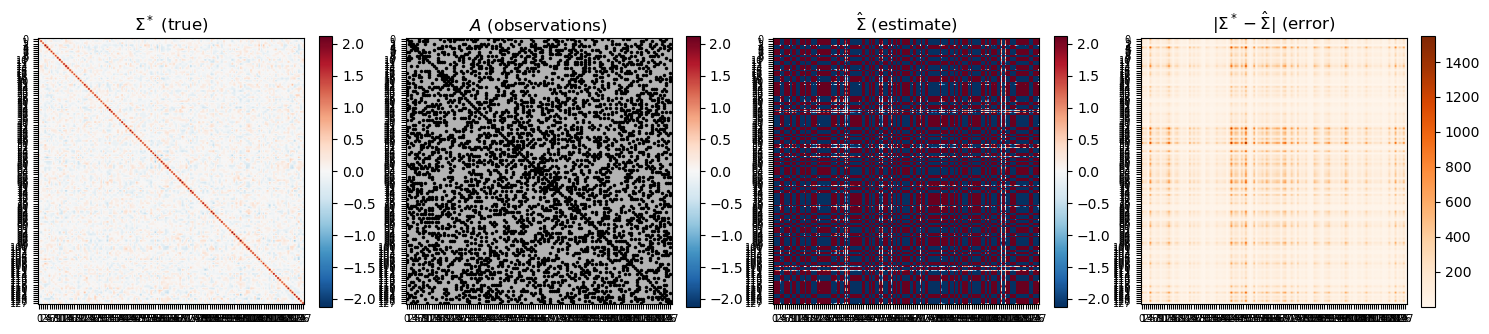

In [106]:
# Observed-entry mask (upper triangle for display)
obs_mask = np.zeros((d, d), dtype=bool)
obs_mask[inds[:, 0], inds[:, 1]] = True
obs_mask[inds[:, 1], inds[:, 0]] = True

vmin = min(Sigma_true.min(), Sigma_hat.min())
vmax = max(Sigma_true.max(), Sigma_hat.max())

fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))

titles  = [r"$\Sigma^*$ (true)", r"$A$ (observations)",
           r"$\hat\Sigma$ (estimate)", r"$|\Sigma^* - \hat\Sigma|$ (error)"]

v = np.max(np.abs(Sigma_true))

# Panel 1: true covariance
im = axes[0].imshow(Sigma_true, vmin=-v, vmax=v, cmap='RdBu_r')
axes[0].set_title(titles[0])
plt.colorbar(im, ax=axes[0], fraction=0.046)


# Panel 2: observations — show only the observed entries; grey out the rest
A_display = np.full((d, d), np.nan)
A_display[obs_mask] = A[obs_mask]
axes[1].imshow(np.ones((d, d)), cmap='Greys', vmin=0, vmax=1, alpha=0.3)   # grey background
im2 = axes[1].imshow(A_display, vmin=-v, vmax=v, cmap='RdBu_r')       # observed values
# Mark observed entries with a dot
for (i, j) in inds:
    axes[1].plot(j, i, 'k.', markersize=3)
    if i != j:
        axes[1].plot(i, j, 'k.', markersize=3)
axes[1].set_title(titles[1])
plt.colorbar(im2, ax=axes[1], fraction=0.046)

# Panel 3: estimate
im3 = axes[2].imshow(Sigma_hat, vmin=-v, vmax=v, cmap='RdBu_r')
axes[2].set_title(titles[2])
plt.colorbar(im3, ax=axes[2], fraction=0.046)

# Panel 4: absolute error
err = np.abs(Sigma_true - Sigma_hat)
im4 = axes[3].imshow(err, cmap='Oranges')
axes[3].set_title(titles[3])
plt.colorbar(im4, ax=axes[3], fraction=0.046)

for ax in axes:
    ax.set_xticks(range(d))
    ax.set_yticks(range(d))
    ax.tick_params(labelsize=7)

plt.tight_layout()
plt.show()

## Per-iteration diagnostics

KKT residuals at final iterate:
  min eig X        = 1.000e-08   (≥ 0 required)
  min eig ∇f̃(X)    = -1.837e-08   (≥ 0 required)
  |⟨∇f̃(X), X⟩|     = 7.780e-07   (= 0 required)


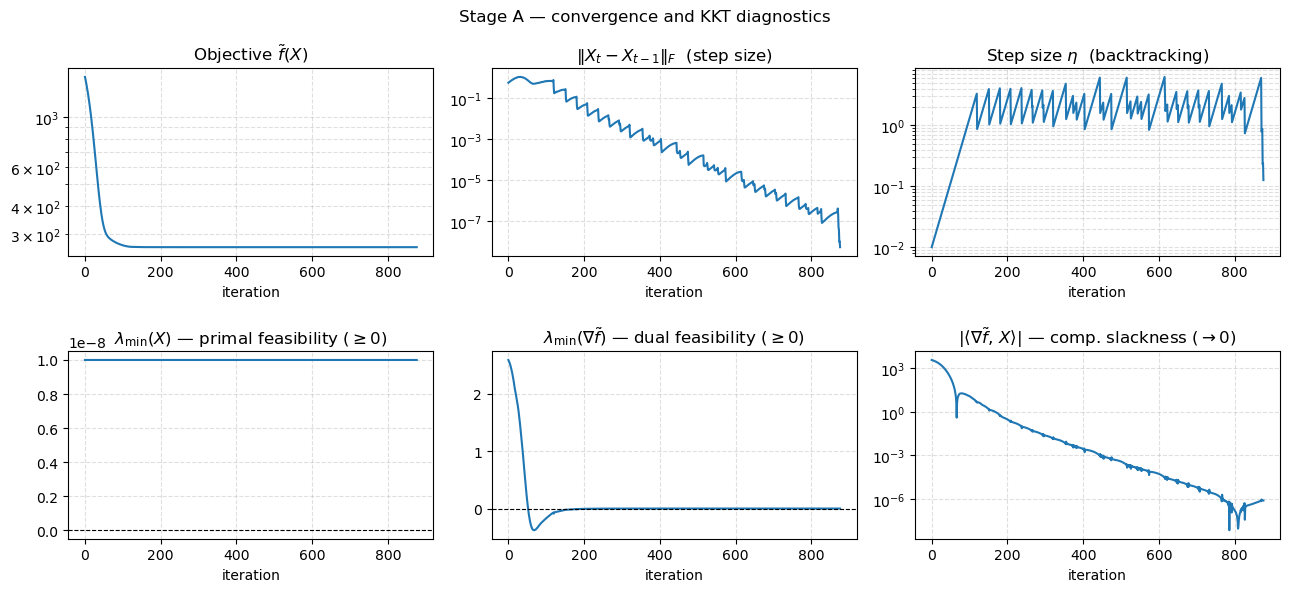

In [107]:
iters = range(len(hist_a))
obj        = [h['obj']        for h in hist_a]
delta      = [h['delta']      for h in hist_a]
eta_vals   = [h['eta']        for h in hist_a]
has_kkt    = 'min_eig_X' in hist_a[0]

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
fig.suptitle("Stage A — convergence and KKT diagnostics", fontsize=12)

# ── top row: standard convergence ────────────────────────────────────────────
axes[0, 0].semilogy(iters, obj)
axes[0, 0].set_title("Objective $\\tilde{f}(X)$")

axes[0, 1].semilogy(iters, delta)
axes[0, 1].set_title(r"$\|X_t - X_{t-1}\|_F$  (step size)")

axes[0, 2].semilogy(iters, eta_vals)
axes[0, 2].set_title(r"Step size $\eta$  (backtracking)")

# ── bottom row: KKT residuals ─────────────────────────────────────────────────
if has_kkt:
    min_eig_X  = [h['min_eig_X']  for h in hist_a]
    min_eig_G  = [h['min_eig_G']  for h in hist_a]
    comp_slack = [h['comp_slack'] for h in hist_a]

    axes[1, 0].plot(iters, min_eig_X)
    axes[1, 0].axhline(0, color='k', linewidth=0.8, linestyle='--')
    axes[1, 0].set_title(r"$\lambda_{\min}(X)$ — primal feasibility ($\geq 0$)")

    axes[1, 1].plot(iters, min_eig_G)
    axes[1, 1].axhline(0, color='k', linewidth=0.8, linestyle='--')
    axes[1, 1].set_title(r"$\lambda_{\min}(\nabla\tilde{f})$ — dual feasibility ($\geq 0$)")

    axes[1, 2].semilogy(iters, np.maximum(comp_slack, 1e-16))
    axes[1, 2].set_title(r"$|\langle\nabla\tilde{f},\,X\rangle|$ — comp. slackness ($\to 0$)")

    print("KKT residuals at final iterate:")
    print(f"  min eig X        = {min_eig_X[-1]:.3e}   (≥ 0 required)")
    print(f"  min eig ∇f̃(X)    = {min_eig_G[-1]:.3e}   (≥ 0 required)")
    print(f"  |⟨∇f̃(X), X⟩|     = {comp_slack[-1]:.3e}   (= 0 required)")
else:
    for ax in axes[1]:
        ax.text(0.5, 0.5, "track_kkt=False", transform=ax.transAxes,
                ha='center', va='center', color='grey')

for ax in axes.flat:
    ax.set_xlabel("iteration")
    ax.grid(True, which='both', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

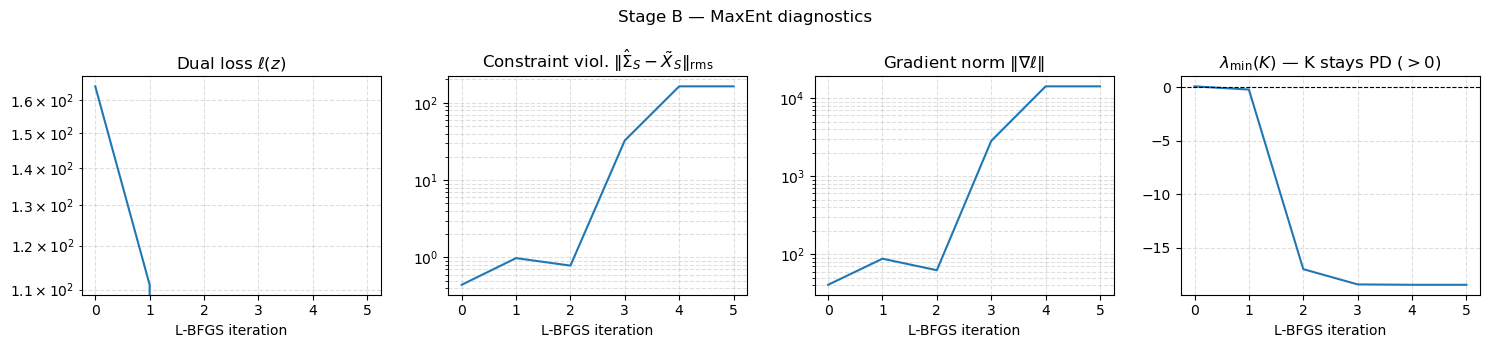

Stage B summary at convergence:
  log|Σ̂|  (entropy)   = -192.0661
  min eig K           = -1.84e+01
  constraint viol rms = 1.63e+02
  gradient norm       = 1.41e+04


In [108]:
iters_b = range(len(hist_b))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
fig.suptitle("Stage B — MaxEnt diagnostics", fontsize=12)

axes[0].semilogy(iters_b, [h['loss']            for h in hist_b])
axes[0].set_title(r"Dual loss $\ell(z)$")

axes[1].semilogy(iters_b, [h['constraint_viol'] for h in hist_b])
axes[1].set_title(r"Constraint viol. $\|\hat\Sigma_S - \tilde X_S\|_{\rm rms}$")

axes[2].semilogy(iters_b, [h['grad_norm']       for h in hist_b])
axes[2].set_title(r"Gradient norm $\|\nabla\ell\|$")

axes[3].plot(iters_b, [h['min_eig_K'] for h in hist_b])
axes[3].axhline(0, color='k', linewidth=0.8, linestyle='--')
axes[3].set_title(r"$\lambda_{\min}(K)$ — K stays PD ($> 0$)")

for ax in axes:
    ax.set_xlabel("L-BFGS iteration")
    ax.grid(True, which='both', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

# Entropy is only meaningful at convergence (dual iterates are not primal-feasible)
logdet_Sigma_hat = np.linalg.slogdet(Sigma_hat)[1]
print("Stage B summary at convergence:")
print(f"  log|Σ̂|  (entropy)   = {logdet_Sigma_hat:.4f}")
print(f"  min eig K           = {hist_b[-1]['min_eig_K']:.2e}")
print(f"  constraint viol rms = {hist_b[-1]['constraint_viol']:.2e}")
print(f"  gradient norm       = {hist_b[-1]['grad_norm']:.2e}")

## Interior Point Method

Minimise $\phi_\mu(X) = f(X) - \mu\log|X|$ over $X \succ 0$, decreasing $\mu \to 0$.  Since the barrier $-\log|X|$ equals (up to sign) the Gaussian entropy, the central path converges directly to the **max-entropy** solution.

Two parameterisations are provided as separate functions (rather than one function with a flag), because the gradient computations are fundamentally different and merging them would obscure both:

| | `ipm_chol` | `ipm_lowertriang` |
|---|---|---|
| Parameters | lower triangle of $L$, $X=LL^T$ | lower triangle of $X$ directly |
| Convexity | non-convex in $L$ | convex in $z$ |
| PD guarantee | bounds $L_{ii} \ge \varepsilon$ | log-barrier + line-search rejection |
| Gradient cost | $O(|S|d)$ — **no inverse** | $O(d^3)$ — requires $X^{-1}$ |
| Key identity | $\log|LL^T| = 2\sum_i \log L_{ii}$ → barrier gradient is diagonal-only | standard chain rule |

In [109]:
def ipm_chol(A, inds, tau, mu0=1.0, rho=0.5, eps=1e-6, eps_coarse=1e-2, max_outer=40, max_inner=200):
    """
    IPM with Cholesky parameterisation X = L Lᵀ  (L lower triangular, L[i,i] > 0).

    Gradient of φ_μ = f(X) - μ log|X| w.r.t. L (lower triangle):
      ∂φ/∂L[i,j] = 2(G·L)[i,j]                    off-diagonal (i > j)
      ∂φ/∂L[i,i] = 2(G·L)[i,i] − 2μ/L[i,i]        diagonal

    Key: log|LLᵀ| = 2 Σᵢ log L[i,i], so the barrier gradient is diagonal-only
    — no matrix inverse required.  G·L costs O(|S|·d) if G is treated as sparse.

    X ≻ 0 is guaranteed by the bound L[i,i] ≥ ε (no PD check needed).
    Note: φ_μ is non-convex in L; in practice this is not an issue.
    """
    d = A.shape[0]
    rows_obs, cols_obs = inds[:, 0], inds[:, 1]
    diag_d = np.arange(d)

    w = 1.0 / tau ** 2
    w /= w.max()
    W = np.zeros((d, d))
    W[rows_obs, cols_obs] = w
    W[cols_obs, rows_obs] = w
    mask = W > 0

    tril_r, tril_c = np.tril_indices(d)
    is_diag = (tril_r == tril_c)

    bounds = [(1e-8, None) if is_diag[k] else (None, None) for k in range(len(tril_r))]

    def vec_to_L(z):
        L = np.zeros((d, d))
        L[tril_r, tril_c] = z
        return L

    # Initialise: X₀ = α I  →  L₀ = √α I
    alpha = max(float(np.mean(np.abs(np.diag(A)))), 1.0)
    z = np.where(is_diag, np.sqrt(alpha), 0.0)

    mu = mu0
    hist = []

    for _outer in range(max_outer):
        eps_inner = min(mu, eps_coarse)

        def phi_and_grad(z, _mu=mu):
            L = vec_to_L(z)
            diag_L = L[diag_d, diag_d]

            # log|LLᵀ| = 2 Σᵢ log L[i,i]  — O(d), no eigendecomposition
            logdet = 2.0 * np.sum(np.log(diag_L))

            X = L @ L.T
            r = X[rows_obs, cols_obs] - A[rows_obs, cols_obs]
            fval = float(np.sum(w * r ** 2))

            G = np.where(mask, W * (X - A), 0.0)
            G[diag_d, diag_d] *= 2

            # Gradient w.r.t. lower triangle of L:
            #   ∂φ/∂L = 2·(G·L)  with diagonal adjusted for barrier
            # Barrier contributes only on diagonal (log|X| = 2Σ log L[i,i])
            # G·L costs O(|S|·d) with sparse G; here dense for simplicity
            GL = G @ L
            grad_z = 2.0 * GL[tril_r, tril_c]
            grad_z[is_diag] -= 2.0 * _mu / diag_L

            return float(fval - _mu * logdet), grad_z

        result = minimize(phi_and_grad, z, method='L-BFGS-B', jac=True,
                          bounds=bounds,
                          options={'maxiter': max_inner, 'ftol': 0, 'gtol': eps_inner})
        z = result.x
        L_opt = vec_to_L(z)
        X = L_opt @ L_opt.T

        # Diagnostics
        r = X[rows_obs, cols_obs] - A[rows_obs, cols_obs]
        fval = float(np.sum(w * r ** 2))
        G = np.where(mask, W * (X - A), 0.0)
        G[diag_d, diag_d] *= 2
        logdet = 2.0 * np.sum(np.log(z[is_diag]))   # cheap, from L diagonal

        hist.append({
            'mu':          mu,
            'obj':         fval,
            'entropy':     logdet,
            'obs_rms':     float(np.sqrt(np.mean(r ** 2))),
            'inner_iters': result.nit,
            'min_eig_X':   float(np.linalg.eigvalsh(X).min()),
            'min_eig_G':   float(np.linalg.eigvalsh(G).min()),
            'comp_slack':  float(abs(np.sum(G * X))),
        })

        if mu <= eps:
            break
        mu *= rho

    return project_psd(X), hist


# THIS VERSION NOT USED - WAS NOT YET ABLE TO MAKE IT STABLE/CORRECT
def ipm_lowertriang(A, inds, tau, mu0=1.0, rho=0.5, eps=1e-6, eps_coarse=1e-2, max_outer=40, max_inner=200):
    """
    IPM with lower-triangle parameterisation of X directly.

    Gradient of φ_μ = f(X) - μ log|X| w.r.t. lower triangle of X:
      ∂φ/∂z_k = mult_k · (G − μ X⁻¹)[i_k, j_k]
    where mult_k = 1 (diagonal), 2 (off-diagonal) — standard chain rule.

    Requires X⁻¹ each inner step: O(d³).  Convex in z.

    Stability note: X can drift near the PSD boundary as μ → 0 (the barrier
    weakens and X⁻¹ blows up).  This is structurally more fragile than ipm_chol
    where L[i,i] ≥ ε keeps X bounded away from singular.  When a trial step
    leaves the PSD cone we return a regularised gradient (not zeros) so that
    scipy's cubic line-search interpolation backtracks correctly.
    """
    d = A.shape[0]
    rows_obs, cols_obs = inds[:, 0], inds[:, 1]
    diag_d = np.arange(d)

    w = 1.0 / tau ** 2
    w /= w.max()
    W = np.zeros((d, d))
    W[rows_obs, cols_obs] = w
    W[cols_obs, rows_obs] = w
    mask = W > 0

    tril_r, tril_c = np.tril_indices(d)
    mult = np.where(tril_r != tril_c, 2.0, 1.0)

    def vec_to_sym(z):
        X = np.zeros((d, d))
        X[tril_r, tril_c] = z
        X = X + X.T
        X[diag_d, diag_d] /= 2
        return X

    def _grad_at(X_eval, _mu):
        """Gradient of φ_μ at X_eval (assumed PD or regularised to be PD)."""
        G = np.where(mask, W * (X_eval - A), 0.0)
        G[diag_d, diag_d] *= 2
        return mult * (G - _mu * np.linalg.inv(X_eval))[tril_r, tril_c]

    # Initialise: X₀ = α I
    alpha = max(float(np.mean(np.abs(np.diag(A)))), 1.0)
    z = np.where(tril_r == tril_c, alpha, 0.0).astype(float)

    mu = mu0
    hist = []

    for _outer in range(max_outer):
        eps_inner = min(mu, eps_coarse)

        def phi_and_grad(z, _mu=mu):
            X = vec_to_sym(z)
            sign, logdet = np.linalg.slogdet(X)
            if sign <= 0:
                # Regularise to nearest PD point and return its gradient.
                # Returning zeros here would corrupt scipy's cubic line-search
                # interpolation (which uses gradients at both bracket endpoints).
                shift = -np.linalg.eigvalsh(X).min() + 1e-4
                X_reg = X + shift * np.eye(d)
                return 1e300, _grad_at(X_reg, _mu)
            r = X[rows_obs, cols_obs] - A[rows_obs, cols_obs]
            fval = float(np.sum(w * r ** 2))
            G = np.where(mask, W * (X - A), 0.0)
            G[diag_d, diag_d] *= 2
            grad_z = mult * (G - _mu * np.linalg.inv(X))[tril_r, tril_c]
            return float(fval - _mu * logdet), grad_z

        result = minimize(phi_and_grad, z, method='L-BFGS-B', jac=True,
                          options={'maxiter': max_inner, 'ftol': 0, 'gtol': eps_inner})
        z = result.x
        X = vec_to_sym(z)

        # Diagnostics
        r = X[rows_obs, cols_obs] - A[rows_obs, cols_obs]
        fval = float(np.sum(w * r ** 2))
        G = np.where(mask, W * (X - A), 0.0)
        G[diag_d, diag_d] *= 2
        sign, logdet = np.linalg.slogdet(X)

        hist.append({
            'mu':          mu,
            'obj':         fval,
            'entropy':     float(logdet) if sign > 0 else -np.inf,
            'obs_rms':     float(np.sqrt(np.mean(r ** 2))),
            'inner_iters': result.nit,
            'min_eig_X':   float(np.linalg.eigvalsh(X).min()),
            'min_eig_G':   float(np.linalg.eigvalsh(G).min()),
            'comp_slack':  float(abs(np.sum(G * X))),
        })

        if mu <= eps:
            break
        mu *= rho

    return project_psd(X), hist

In [110]:
Sigma_ipm, hist_ipm = ipm_chol(A, inds, tau, eps=1e-10)
#Sigma_ipm, hist_ipm = ipm_lowertriang(A, inds, tau, eps=1e-10)

w_norm = (1.0 / tau ** 2)
w_norm = w_norm / w_norm.max()

def weighted_obj(Sigma):
    r = Sigma[inds[:, 0], inds[:, 1]] - A[inds[:, 0], inds[:, 1]]
    return float(np.sum(w_norm * r ** 2))

print(f"{'Metric':<30} {'PGD-MaxEnt':>12} {'IPM':>12}")
print("-" * 56)

rows = [
    ("Weighted obj f(X)",        weighted_obj(Sigma_hat),                    weighted_obj(Sigma_ipm)),
    ("Frobenius error",          np.linalg.norm(Sigma_true - Sigma_hat),     np.linalg.norm(Sigma_true - Sigma_ipm)),
    ("Entropy log|Σ̂|",          np.linalg.slogdet(Sigma_hat)[1],            np.linalg.slogdet(Sigma_ipm)[1]),
    ("Min eigenvalue",           np.linalg.eigvalsh(Sigma_hat).min(),        np.linalg.eigvalsh(Sigma_ipm).min()),
]
for label, pgd_val, ipm_val in rows:
    print(f"  {label:<28} {pgd_val:>12.4f} {ipm_val:>12.4f}")

print(f"\n  IPM: {len(hist_ipm)} outer iters, {sum(h['inner_iters'] for h in hist_ipm)} total inner L-BFGS steps")

Metric                           PGD-MaxEnt          IPM
--------------------------------------------------------
  Weighted obj f(X)            16979566.5105     262.9155
  Frobenius error                19759.8062      62.8978
  Entropy log|Σ̂|                 -192.0661   -1902.1745
  Min eigenvalue                    -3.9794       0.0000

  IPM: 35 outer iters, 5292 total inner L-BFGS steps


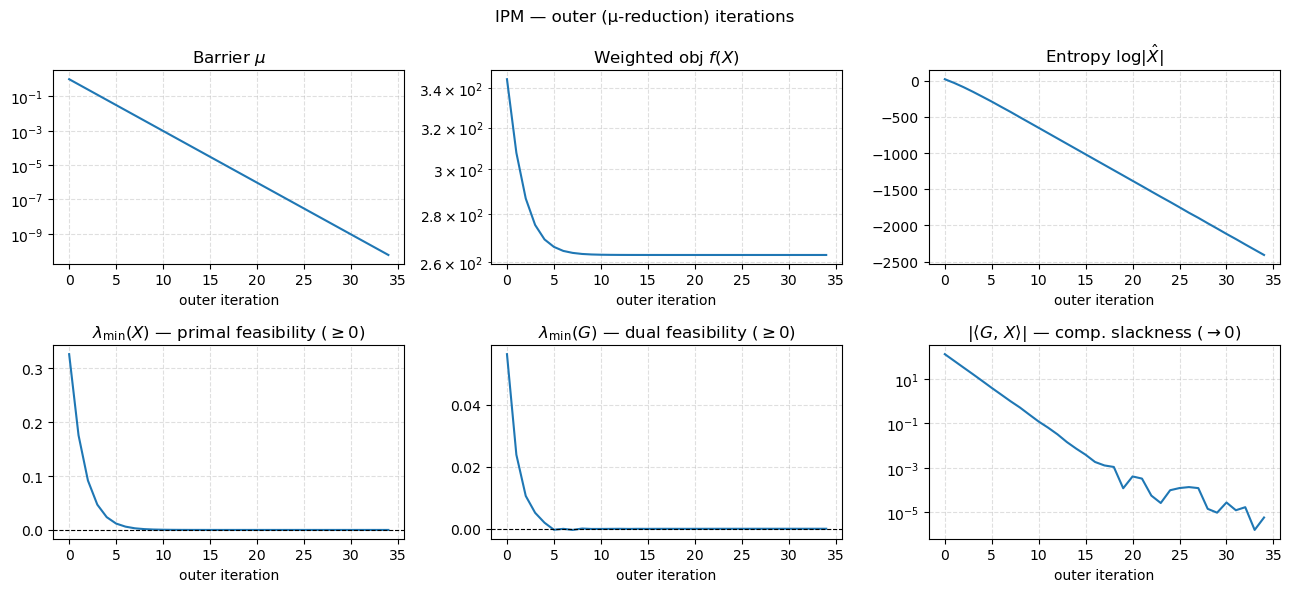

Total inner L-BFGS steps: 5292

KKT residuals at final iterate:
  min eig X      = 2.188e-11   (≥ 0 required)
  min eig G      = -5.518e-07   (≥ 0 required)
  |⟨G, X⟩|       = 5.922e-06   (= 0 required)


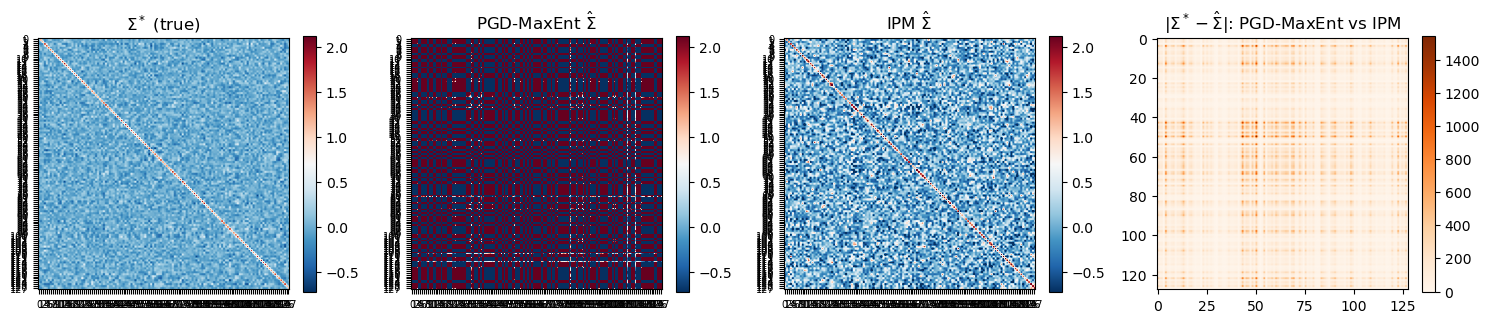

In [111]:
iters_outer = range(len(hist_ipm))

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
fig.suptitle("IPM — outer (μ-reduction) iterations", fontsize=12)

# ── top row: optimisation progress ───────────────────────────────────────────
axes[0, 0].semilogy(iters_outer, [h['mu']      for h in hist_ipm])
axes[0, 0].set_title(r"Barrier $\mu$")

axes[0, 1].semilogy(iters_outer, [h['obj']     for h in hist_ipm])
axes[0, 1].set_title(r"Weighted obj $f(X)$")

axes[0, 2].plot(iters_outer, [h['entropy']     for h in hist_ipm])
axes[0, 2].set_title(r"Entropy $\log|\hat X|$")

# ── bottom row: KKT residuals (same convention as Stage A) ───────────────────
min_eig_X  = [h['min_eig_X']  for h in hist_ipm]
min_eig_G  = [h['min_eig_G']  for h in hist_ipm]
comp_slack = [h['comp_slack'] for h in hist_ipm]

axes[1, 0].plot(iters_outer, min_eig_X)
axes[1, 0].axhline(0, color='k', linewidth=0.8, linestyle='--')
axes[1, 0].set_title(r"$\lambda_{\min}(X)$ — primal feasibility ($\geq 0$)")

axes[1, 1].plot(iters_outer, min_eig_G)
axes[1, 1].axhline(0, color='k', linewidth=0.8, linestyle='--')
axes[1, 1].set_title(r"$\lambda_{\min}(G)$ — dual feasibility ($\geq 0$)")

axes[1, 2].semilogy(iters_outer, np.maximum(comp_slack, 1e-16))
axes[1, 2].set_title(r"$|\langle G,\,X\rangle|$ — comp. slackness ($\to 0$)")

for ax in axes.flat:
    ax.set_xlabel("outer iteration")
    ax.grid(True, which='both', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

print(f"Total inner L-BFGS steps: {sum(h['inner_iters'] for h in hist_ipm)}")
print("\nKKT residuals at final iterate:")
print(f"  min eig X      = {min_eig_X[-1]:.3e}   (≥ 0 required)")
print(f"  min eig G      = {min_eig_G[-1]:.3e}   (≥ 0 required)")
print(f"  |⟨G, X⟩|       = {comp_slack[-1]:.3e}   (= 0 required)")

# ── Side-by-side error comparison ─────────────────────────────────────────────
vmin = Sigma_true.min()
vmax = Sigma_true.max()
err_pgd = np.abs(Sigma_true - Sigma_hat)
err_ipm = np.abs(Sigma_true - Sigma_ipm)
emax = max(err_pgd.max(), err_ipm.max())
delta_pgd_ipm = np.abs(err_pgd - err_ipm)
delta_max = delta_pgd_ipm.max()

fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))

im0 = axes[0].imshow(Sigma_true, vmin=vmin, vmax=vmax, cmap='RdBu_r')
axes[0].set_title(r"$\Sigma^*$ (true)")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(Sigma_hat, vmin=vmin, vmax=vmax, cmap='RdBu_r')
axes[1].set_title(r"PGD-MaxEnt $\hat\Sigma$")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

im2 = axes[2].imshow(Sigma_ipm, vmin=vmin, vmax=vmax, cmap='RdBu_r')
axes[2].set_title(r"IPM $\hat\Sigma$")
plt.colorbar(im2, ax=axes[2], fraction=0.046)

im3 = axes[3].imshow(delta_pgd_ipm, cmap='Oranges', vmin=0, vmax=delta_max)
axes[3].set_title(r"$|\Sigma^* - \hat\Sigma|$: PGD-MaxEnt vs IPM")
plt.colorbar(im3, ax=axes[3], fraction=0.046)

# im3 = axes[3].imshow(np.hstack([err_pgd, err_ipm]), cmap='Oranges', vmin=0, vmax=emax)
# axes[3].set_title(r"$|\Sigma^* - \hat\Sigma|$: PGD-MaxEnt | IPM")
# plt.colorbar(im3, ax=axes[3], fraction=0.046)

for ax in axes[:3]:
    ax.set_xticks(range(d)); ax.set_yticks(range(d)); ax.tick_params(labelsize=7)

plt.tight_layout()
plt.show()